<a href="https://colab.research.google.com/github/ananyachikkur-cs/signal-and-system-lab/blob/main/exampractice_txt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

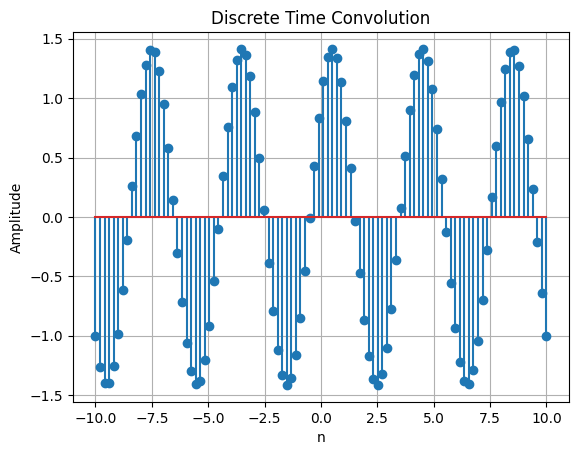

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Input signal
k = np.arange(-5, 5)
x = np.ones(len(k))

# Output range
n = np.linspace(-10, 10, 100)

# Impulse response
def h(n):
    return np.cos(np.pi*n/2)

# Discrete convolution using sum()
y = []

for i in n:
    con = sum(x[j] * h(i-j) for j in range(len(k)))
    y.append(con)

# Plot
plt.stem(n, y)
plt.xlabel('n')
plt.ylabel('Amplitude')
plt.title('Discrete Time Convolution')
plt.grid()
plt.show()


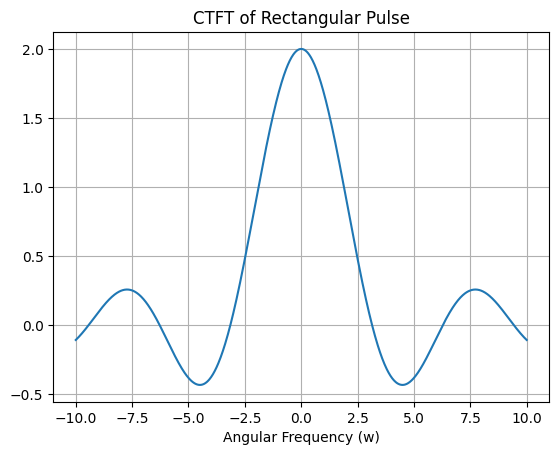

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

t, w_sym = sp.symbols('t w', real=True)
x = sp.Piecewise((1, (t >= -1) & (t <= 1)), (0, True))

# Compute the CTFT (multiplying by exp(-i*w*t))
x1 = sp.integrate(x * sp.exp(-sp.I * w_sym * t), (t, -sp.oo, sp.oo))

# Lambdify the analytical transform expression
y = sp.lambdify(w_sym, x1, 'numpy')


# Numerical frequency values (using w_vals to avoid overriding the symbol)
w_vals = np.linspace(-10, 10, 1000)

# Plotting the CTFT (magnitude)
plt.plot(w_vals, y(w_vals))
plt.xlabel('Angular Frequency (w)')
plt.title('CTFT of Rectangular Pulse')
plt.grid()
plt.show()

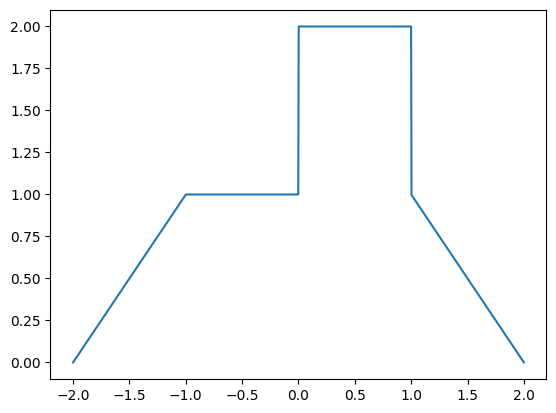

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

t = sp.symbols('t')
x = (t+2)*sp.Heaviside(t+2) - (t+1)*sp.Heaviside(t+1) + sp.Heaviside(t) - sp.Heaviside(t-1) - (t-1)*sp.Heaviside(t-1) + (t-2)*sp.Heaviside(t-2)
x1 = sp.lambdify(t,x)
t = np.linspace(-2,2,1000)
plt.plot(t, x1(t))


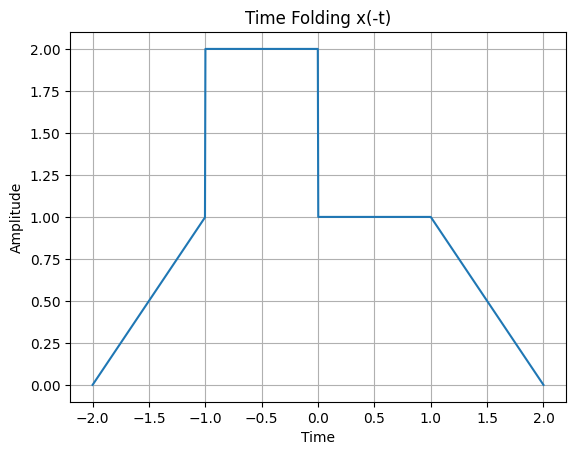

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

t = sp.symbols('t')

x = (t+2)*sp.Heaviside(t+2) - (t+1)*sp.Heaviside(t+1) + sp.Heaviside(t) - sp.Heaviside(t-1) - (t-1)*sp.Heaviside(t-1) + (t-2)*sp.Heaviside(t-2)

# Time folding
x1 = x.replace(t, -t)

y = sp.lambdify(t, x1, 'numpy')

t = np.linspace(-2, 2, 1000)

plt.plot(t, y(t))
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.title('Time Folding x(-t)')
plt.grid()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
t = sp.symbols('t')
x = -1*(-t-1)*sp.Heaviside(-t-1) + (+t+2)*sp.Heaviside(+t+2) + sp.Heaviside(-t-2)
x1 = sp.lambdify(t,x)
t = np.linspace(-3,3,1000)
plt.plot(t, x1(t))
plt.grid(1)

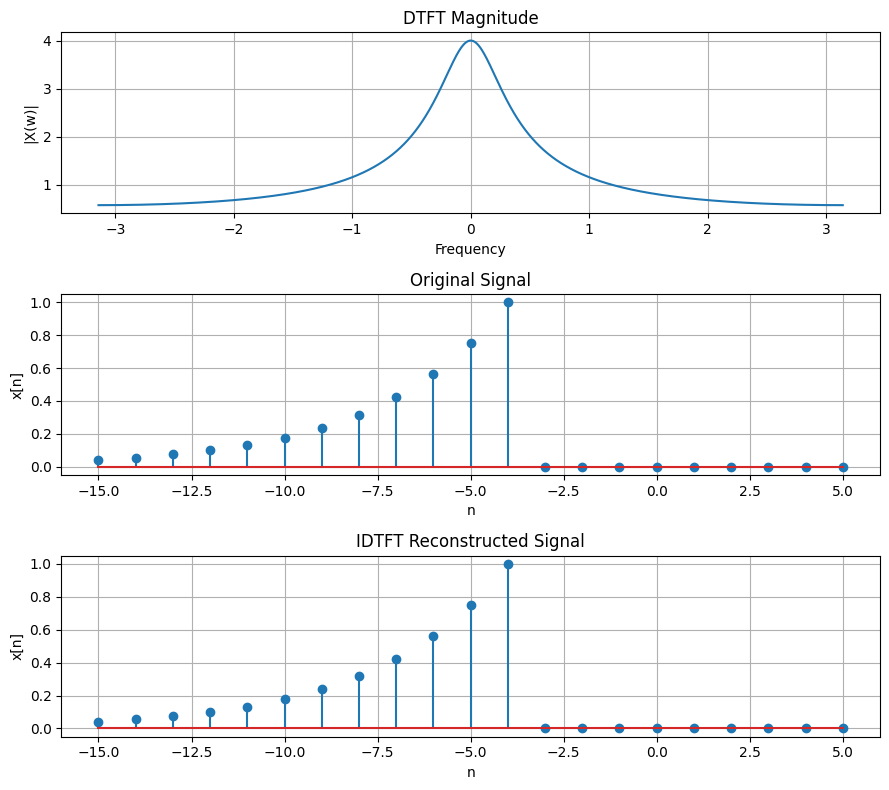

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Frequency range
w = np.linspace(-np.pi, np.pi, 4096, endpoint=False)

# DTFT
X = np.exp(1j*4*w)/(1-(3/4)*np.exp(1j*w))

# Time range
n = np.arange(-15, 6)

# Original signal
x = np.where(n <= -4, (3/4)**(-n-4), 0)

# IDTFT
xr = np.zeros(len(n), dtype=complex)

for i in range(len(n)):
    xr[i] = np.sum(X*np.exp(1j*w*n[i]))/len(w)

# Plot DTFT magnitude
plt.figure(figsize=(9,8))

plt.subplot(3,1,1)
plt.plot(w, np.abs(X))
plt.title('DTFT Magnitude')
plt.xlabel('Frequency')
plt.ylabel('|X(w)|')
plt.grid()

# Original signal
plt.subplot(3,1,2)
plt.stem(n, x)
plt.title('Original Signal')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.grid()

# Reconstructed signal
plt.subplot(3,1,3)
plt.stem(n, np.real(xr))
plt.title('IDTFT Reconstructed Signal')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.grid()

plt.tight_layout()
plt.show()

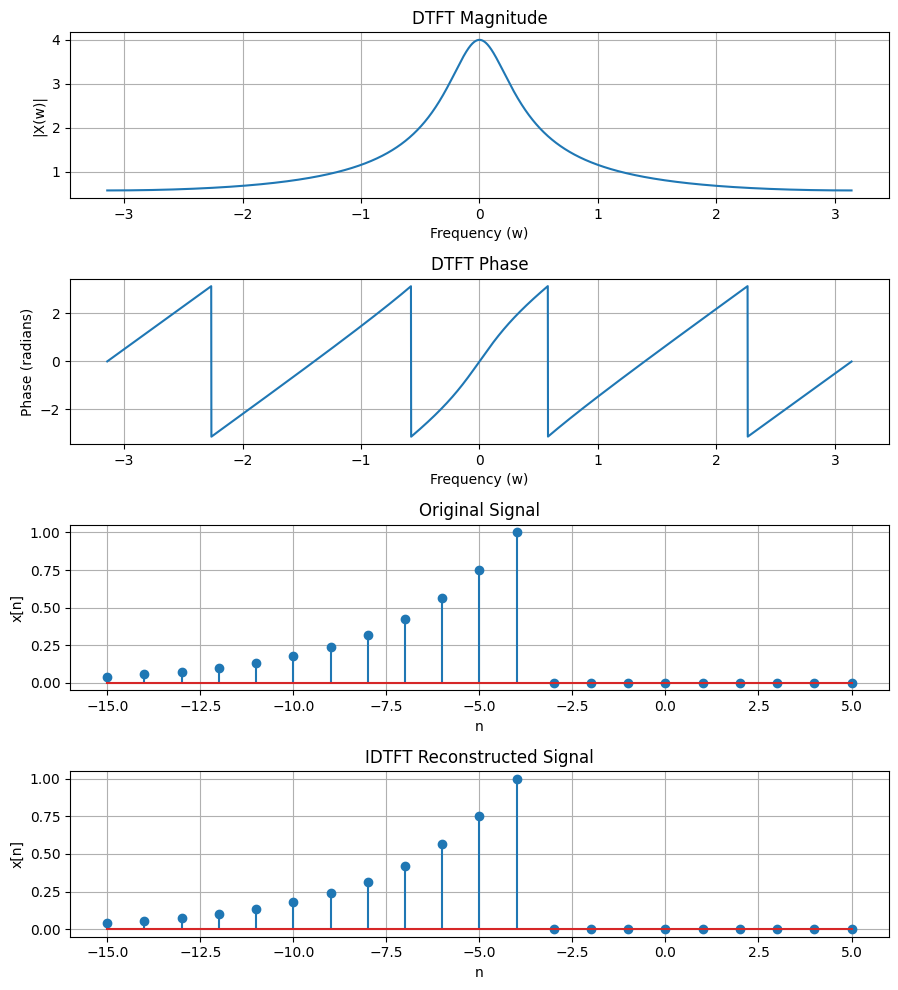

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Frequency range
w = np.linspace(-np.pi, np.pi, 4096, endpoint=False)

# DTFT
X = np.exp(1j*4*w)/(1-(3/4)*np.exp(1j*w))

# Time range
n = np.arange(-15, 6)

# Original signal
x = np.where(n <= -4, (3/4)**(-n-4), 0)

# IDTFT
xr = np.zeros(len(n), dtype=complex)

for i in range(len(n)):
    xr[i] = np.sum(X*np.exp(1j*w*n[i]))/len(w)

# Plotting
plt.figure(figsize=(9,10))

plt.subplot(4,1,1)
plt.plot(w, np.abs(X))
plt.title('DTFT Magnitude')
plt.xlabel('Frequency (w)')
plt.ylabel('|X(w)|')
plt.grid()

plt.subplot(4,1,2)
plt.plot(w, np.angle(X))
plt.title('DTFT Phase')
plt.xlabel('Frequency (w)')
plt.ylabel('Phase (radians)')
plt.grid()

plt.subplot(4,1,3)
plt.stem(n, x)
plt.title('Original Signal')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.grid()

plt.subplot(4,1,4)
plt.stem(n, np.real(xr))
plt.title('IDTFT Reconstructed Signal')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.grid()

plt.tight_layout()
plt.show()